# Задача №4. Оптимизация рекламной нагрузки для платформы видеоконтента

**Платформа:** «ВидеоСервис»

Решение построено по четырём частям и десяти вопросам. Все числовые таблицы и выводы рассчитываются по формулам на основе JSON-конфигурации.

## Условие задачи

Платформа **«ВидеоСервис»** зарабатывает на рекламе и подписке. Необходимо найти оптимальную рекламную нагрузку, максимизирующую общую прибыль платформы.

Для каждого уровня рекламной нагрузки заданы отток пользователей и среднее время просмотра. Эти параметры используются при расчёте дохода подписки и потерь оттока.

In [15]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from utils.calculations import calculate_scenarios, best_scenario, format_rub, format_mln
CONFIG = json.loads((ROOT / 'data' / 'task_04_ad_load_config.json').read_text(encoding='utf-8'))
plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.edgecolor': '#4F5B66', 'axes.labelcolor': '#263238', 'xtick.color': '#263238', 'ytick.color': '#263238'})
base = calculate_scenarios(CONFIG)
print(f"Платформа: {CONFIG['platform']}; активных пользователей: {format_rub(CONFIG['active_users'])}")

Платформа: ВидеоСервис; активных пользователей: 5 000 000


In [16]:
# Исходные данные динамически загружаются из JSON
input_data = pd.DataFrame({
    'Показатель': ['Число активных пользователей', 'Доход от подписки', 'Доход от рекламы (CPM)', 'Среднее число видео в день', 'CAC', 'Средний срок жизни пользователя', 'Ставка дисконтирования'],
    'Значение': [format_rub(CONFIG['active_users']) + ' чел.', format_rub(CONFIG['subscription_arpu_rub_month']) + ' руб./пользователь в месяц', format_rub(CONFIG['cpm_rub']) + ' руб./1 000 показов', format_rub(CONFIG['videos_per_user_day']) + ' видео', format_rub(CONFIG['cac_rub']) + ' руб./пользователь', format_rub(CONFIG['lifetime_months']) + ' мес.', f"{CONFIG['discount_rate_annual']*100:.0f}".replace('.', ',') + '% годовых']
})
display(input_data)
influence = pd.DataFrame({'Рекламная нагрузка, показов/день': CONFIG['load_levels_impressions_day'], 'Отток пользователей, %': [f'{x*100:.1f}'.replace('.', ',') + '%' for x in CONFIG['churn_rates']], 'Время просмотра, мин': CONFIG['watch_time_minutes']})
display(influence)

,Показатель,Значение
0,Число активных пользователей,5 000 000 чел.
1,Доход от подписки,300 руб./пользователь в месяц
2,Доход от рекламы (CPM),20 руб./1 000 показов
3,Среднее число видео в день,10 видео
4,CAC,2 000 руб./пользователь
5,Средний срок жизни пользователя,24 мес.
6,Ставка дисконтирования,12% годовых


,"Рекламная нагрузка, показов/день","Отток пользователей, %","Время просмотра, мин"
0,0,"0,0%",120
1,10,"0,0%",115
2,20,"2,0%",110
3,30,"5,0%",100
4,40,"10,0%",90
5,50,"18,0%",75
6,60,"30,0%",60


> **Примечание.** Ставка дисконтирования загружается из JSON и выводится среди исходных данных. В десяти вопросах требуется расчёт месячной прибыли и чувствительности рекламной нагрузки, без расчёта NPV, поэтому ставка не входит в формулу текущей прибыли.

## Часть 1. Расчёт доходов и затрат

### 1.1. Доход от рекламы

Количество показов в месяц:

$$Imp_{month} = Users \times Imp_{day} \times 30.$$

Доход от рекламы:

$$R_{ads} = Imp_{month} \times \frac{CPM}{1000}.$$

In [17]:
ads_table = pd.DataFrame({
    'Нагрузка, показов/день': base['Нагрузка, показов/день'],
    'Показы/мес., млн': CONFIG['active_users'] * base['Нагрузка, показов/день'] * 30 / 1_000_000,
    'Доход рекламный, млн руб.': base['Доход рекламы, руб.'] / 1_000_000
})
for col in ads_table.columns[1:]: ads_table[col] = ads_table[col].map(lambda x: format_rub(x, 1))
display(ads_table)
max_ads = base.loc[base['Доход рекламы, руб.'].idxmax()]
print(f"Вывод 1.1: рекламный доход рассчитывается формулой и растёт с {int(max_ads['Нагрузка, показов/день'])} показами до {format_mln(max_ads['Доход рекламы, руб.'])} млн руб. при максимальной нагрузке.")

,"Нагрузка, показов/день","Показы/мес., млн","Доход рекламный, млн руб."
0,0,"0,0","0,0"
1,10,"1 500,0","30,0"
2,20,"3 000,0","60,0"
3,30,"4 500,0","90,0"
4,40,"6 000,0","120,0"
5,50,"7 500,0","150,0"
6,60,"9 000,0","180,0"


Вывод 1.1: рекламный доход рассчитывается формулой и растёт с 60 показами до 180,0 млн руб. при максимальной нагрузке.


### 1.2. Доход от подписки

Пользователи после оттока:

$$Users_{after} = Users \times (1-Churn).$$

Доход подписки:

$$R_{sub} = Users_{after} \times ARPU.$$

In [18]:
subscription_table = pd.DataFrame({
    'Нагрузка, показов/день': base['Нагрузка, показов/день'],
    'Отток, %': base['Отток, %'],
    'Пользователи после оттока, млн': base['Сохранившиеся пользователи'] / 1_000_000,
    'Доход подписки, млн руб.': base['Доход подписки, руб.'] / 1_000_000
})
subscription_table['Отток, %'] = subscription_table['Отток, %'].map(lambda x: f'{x:.1f}'.replace('.', ',') + '%')
for col in ['Пользователи после оттока, млн', 'Доход подписки, млн руб.']:
    subscription_table[col] = subscription_table[col].map(lambda x: format_rub(x, 2 if 'Пользователи' in col else 1))
display(subscription_table)
lowest_sub = base.loc[base['Доход подписки, руб.'].idxmin()]
print(f"Вывод 1.2: максимальный доход подписки равен {format_mln(base['Доход подписки, руб.'].max())} млн руб. при отсутствии оттока; минимальный — {format_mln(lowest_sub['Доход подписки, руб.'])} млн руб.")

,"Нагрузка, показов/день","Отток, %","Пользователи после оттока, млн","Доход подписки, млн руб."
0,0,"0,0%","5,00","1 500,0"
1,10,"0,0%","5,00","1 500,0"
2,20,"2,0%","4,90","1 470,0"
3,30,"5,0%","4,75","1 425,0"
4,40,"10,0%","4,50","1 350,0"
5,50,"18,0%","4,10","1 230,0"
6,60,"30,0%","3,50","1 050,0"


Вывод 1.2: максимальный доход подписки равен 1 500,0 млн руб. при отсутствии оттока; минимальный — 1 050,0 млн руб.


### 1.3. Потери от оттока

По формуле задания:

$$Loss = Users \times Churn \times CAC + Users \times Churn \times ARPU \times Lifetime.$$

In [19]:
loss_table = pd.DataFrame({
    'Нагрузка, показов/день': base['Нагрузка, показов/день'],
    'Отток, %': base['Отток, %'],
    'Потери CAC, млн руб.': base['Сохранившиеся пользователи'].mul(0).add(CONFIG['active_users'] * base['Отток, %'] / 100 * CONFIG['cac_rub'] / 1_000_000),
    'Потери LTV, млн руб.': CONFIG['active_users'] * base['Отток, %'] / 100 * CONFIG['subscription_arpu_rub_month'] * CONFIG['lifetime_months'] / 1_000_000,
    'Потери оттока, млн руб.': base['Потери оттока, руб.'] / 1_000_000
})
loss_table['Отток, %'] = loss_table['Отток, %'].map(lambda x: f'{x:.1f}'.replace('.', ',') + '%')
for col in loss_table.columns[2:]: loss_table[col] = loss_table[col].map(lambda x: format_rub(x, 1))
display(loss_table)
max_loss = base.loc[base['Потери оттока, руб.'].idxmax()]
print(f"Вывод 1.3: максимальные потери оттока составляют {format_mln(max_loss['Потери оттока, руб.'])} млн руб. при нагрузке {int(max_loss['Нагрузка, показов/день'])} показов в день.")

,"Нагрузка, показов/день","Отток, %","Потери CAC, млн руб.","Потери LTV, млн руб.","Потери оттока, млн руб."
0,0,"0,0%","0,0","0,0","0,0"
1,10,"0,0%","0,0","0,0","0,0"
2,20,"2,0%","200,0","720,0","920,0"
3,30,"5,0%","500,0","1 800,0","2 300,0"
4,40,"10,0%","1 000,0","3 600,0","4 600,0"
5,50,"18,0%","1 800,0","6 480,0","8 280,0"
6,60,"30,0%","3 000,0","10 800,0","13 800,0"


Вывод 1.3: максимальные потери оттока составляют 13 800,0 млн руб. при нагрузке 60 показов в день.


## Часть 2. Оптимизация нагрузки

### 2.1. Общая прибыль

$$\Pi = R_{ads} + R_{sub} - Loss.$$

In [20]:
profit_table = pd.DataFrame({
    'Нагрузка, показов/день': base['Нагрузка, показов/день'],
    'Доход рекламный, млн руб.': base['Доход рекламы, руб.'] / 1_000_000,
    'Доход подписки, млн руб.': base['Доход подписки, руб.'] / 1_000_000,
    'Потери оттока, млн руб.': base['Потери оттока, руб.'] / 1_000_000,
    'Общая прибыль, млн руб.': base['Общая прибыль, руб.'] / 1_000_000
})
for col in profit_table.columns[1:]: profit_table[col] = profit_table[col].map(lambda x: format_rub(x, 1))
display(profit_table)
best = best_scenario(base)
print(f"Вывод 2.1: оптимальная нагрузка = {int(best['Нагрузка, показов/день'])} показов в день; максимальная прибыль = {format_mln(best['Общая прибыль, руб.'])} млн руб.")

,"Нагрузка, показов/день","Доход рекламный, млн руб.","Доход подписки, млн руб.","Потери оттока, млн руб.","Общая прибыль, млн руб."
0,0,"0,0","1 500,0","0,0","1 500,0"
1,10,"30,0","1 500,0","0,0","1 530,0"
2,20,"60,0","1 470,0","920,0","610,0"
3,30,"90,0","1 425,0","2 300,0","-785,0"
4,40,"120,0","1 350,0","4 600,0","-3 130,0"
5,50,"150,0","1 230,0","8 280,0","-6 900,0"
6,60,"180,0","1 050,0","13 800,0","-12 570,0"


Вывод 2.1: оптимальная нагрузка = 10 показов в день; максимальная прибыль = 1 530,0 млн руб.


### 2.2. Рекомендация по нагрузке

Рекомендация формируется по рассчитанному оптимуму. Платным пользователям следует показывать минимум рекламы, поскольку они уже приносят подписную выручку. Бесплатным пользователям можно назначить нагрузку около рассчитанного оптимума с обязательным контролем оттока.

In [21]:
recommended_load = int(best['Нагрузка, показов/день'])
policy = CONFIG['segment_policy']
free_upper_load = recommended_load + int(policy['free_test_range_increment'])
paid_upper_load = int(round(recommended_load * policy['paid_max_fraction_of_optimal_load']))
print(f"Динамический вывод 2.2: для бесплатных пользователей рекомендуется начать с {recommended_load} показов в день и тестировать диапазон до {free_upper_load} показов в день; для платных пользователей — от {policy['inactive_load']} до {paid_upper_load} показов в день.")

Динамический вывод 2.2: для бесплатных пользователей рекомендуется начать с 10 показов в день и тестировать диапазон до 20 показов в день; для платных пользователей — от 0 до 5 показов в день.


### 2.3. График зависимости прибыли от нагрузки

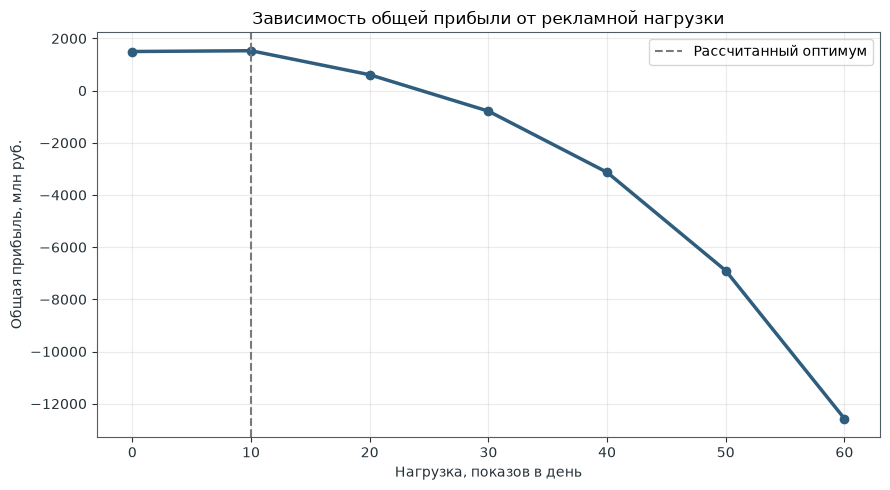

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(base['Нагрузка, показов/день'], base['Общая прибыль, руб.']/1e6, marker='o', linewidth=2.5, color='#2F5D7E')
ax.axvline(best['Нагрузка, показов/день'], color='#7A7A7A', linestyle='--', label='Рассчитанный оптимум')
ax.set_title('Зависимость общей прибыли от рекламной нагрузки')
ax.set_xlabel('Нагрузка, показов в день'); ax.set_ylabel('Общая прибыль, млн руб.')
ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
(ROOT / 'reports' / 'figures').mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / 'reports' / 'figures' / 'task_04_profit_by_load.png', dpi=180, bbox_inches='tight'); plt.show()

## Часть 3. Анализ чувствительности

### 3.1. Изменение CPM

Для каждого значения CPM из JSON расчёт выполняется заново.

In [23]:
cpm_rows=[]
for cpm_value in CONFIG['sensitivity_cpm_rub']:
    scenario = calculate_scenarios(CONFIG, cpm=cpm_value)
    opt = best_scenario(scenario)
    cpm_rows.append({'CPM, руб.': cpm_value, 'Оптимальная нагрузка, показов/день': int(opt['Нагрузка, показов/день']), 'Максимальная прибыль, млн руб.': opt['Общая прибыль, руб.']/1_000_000})
cpm_table=pd.DataFrame(cpm_rows)
cpm_table['Максимальная прибыль, млн руб.']=cpm_table['Максимальная прибыль, млн руб.'].map(lambda x: format_rub(x,1))
display(cpm_table)
print(f"Динамический вывод 3.1: при проверенных значениях CPM оптимум находится в диапазоне от {cpm_table['Оптимальная нагрузка, показов/день'].min()} до {cpm_table['Оптимальная нагрузка, показов/день'].max()} показов в день.")

,"CPM, руб.","Оптимальная нагрузка, показов/день","Максимальная прибыль, млн руб."
0,10,10,"1 515,0"
1,20,10,"1 530,0"
2,30,10,"1 545,0"


Динамический вывод 3.1: при проверенных значениях CPM оптимум находится в диапазоне от 10 до 10 показов в день.


### 3.2. Изменение оттока на ±20%

Для каждого уровня нагрузки рассчитывается прибыль при снижении исходного оттока на 20%, в базовом сценарии и при увеличении оттока на 20%.

In [24]:
churn_rows=[]
churn_numeric=[]
for i, load in enumerate(CONFIG['load_levels_impressions_day']):
    row={'Нагрузка, показов/день': load}
    numeric={'Нагрузка, показов/день': load}
    for label, mult in [('−20%',0.8),('База',1.0),('+20%',1.2)]:
        scenario=calculate_scenarios(CONFIG, churn_multiplier=mult)
        value=scenario.loc[i,'Общая прибыль, руб.']/1_000_000
        row[f'Прибыль, млн руб. ({label})']=value
        numeric[label]=value
    churn_rows.append(row)
    churn_numeric.append(numeric)
churn_numeric_table=pd.DataFrame(churn_numeric)
churn_table=churn_numeric_table.copy()
for col in churn_table.columns[1:]: churn_table[col]=churn_table[col].map(lambda x: format_rub(x,1))
display(churn_table)
base_values=churn_numeric_table['База']
plus_values=churn_numeric_table['+20%']
minus_values=churn_numeric_table['−20%']
worst_load=int(churn_numeric_table.loc[(base_values-plus_values).idxmax(),'Нагрузка, показов/день'])
max_loss_from_churn=float((base_values-plus_values).max())
best_improvement=float((minus_values-base_values).max())
print(f"Динамический вывод 3.2: при росте оттока на 20% максимальное снижение прибыли составляет {format_rub(max_loss_from_churn,1)} млн руб. при нагрузке {worst_load} показов в день.")
print(f"При снижении оттока на 20% максимальное улучшение прибыли составляет {format_rub(best_improvement,1)} млн руб.")

,"Нагрузка, показов/день",−20%,База,+20%
0,0,"1 500,0","1 500,0","1 500,0"
1,10,"1 530,0","1 530,0","1 530,0"
2,20,"800,0","610,0","420,0"
3,30,"-310,0","-785,0","-1 260,0"
4,40,"-2 180,0","-3 130,0","-4 080,0"
5,50,"-5 190,0","-6 900,0","-8 610,0"
6,60,"-9 720,0","-12 570,0","-15 420,0"


Динамический вывод 3.2: при росте оттока на 20% максимальное снижение прибыли составляет 2 850,0 млн руб. при нагрузке 60 показов в день.
При снижении оттока на 20% максимальное улучшение прибыли составляет 2 850,0 млн руб.


## Часть 4. Стратегические рекомендации

### 4.1. Рекомендации по сегментам

In [25]:
segment_recommendations=pd.DataFrame({
    'Сегмент':['Платные пользователи','Бесплатные пользователи','Новые пользователи','Неактивные пользователи'],
    'Рекомендуемая нагрузка':[f"{policy['inactive_load']}–{paid_upper_load} показов/день",f'{recommended_load}–{free_upper_load} показов/день',f"{policy['new_users_min_load']}–{policy['new_users_max_load']} показов/день",f"{policy['inactive_load']} показов/день"],
    'Обоснование':['Сохранение лояльности и подписной выручки','Монетизация при контроле рассчитанного оттока','Снижение риска раннего оттока','Не тратить рекламный инвентарь без активности']
})
display(segment_recommendations)
print(f"Динамический вывод 4.1: диапазон бесплатного сегмента {recommended_load}–{free_upper_load}, платного сегмента {policy['inactive_load']}–{paid_upper_load}; параметры долей и диапазонов загружены из JSON.")

,Сегмент,Рекомендуемая нагрузка,Обоснование
0,Платные пользователи,0–5 показов/день,Сохранение лояльности и подписной выручки
1,Бесплатные пользователи,10–20 показов/день,Монетизация при контроле рассчитанного оттока
2,Новые пользователи,5–10 показов/день,Снижение риска раннего оттока
3,Неактивные пользователи,0 показов/день,Не тратить рекламный инвентарь без активности


Динамический вывод 4.1: диапазон бесплатного сегмента 10–20, платного сегмента 0–5; параметры долей и диапазонов загружены из JSON.


### 4.2. План мониторинга

In [26]:
monitoring=pd.DataFrame({
    'Метрика':['Churn Rate','ARPU','CTR','Время просмотра','NPS'],
    'Частота':['Ежедневно','Еженедельно','Ежедневно','Ежедневно','Ежемесячно'],
    'Целевое значение':['< 2%',f"> {format_rub(CONFIG['subscription_arpu_rub_month'])} руб.",'> 2%',f"≥ {int(CONFIG['watch_time_minutes'][0] * 0.9)} мин",'> 50'],
    'Действие при отклонении':['Снизить нагрузку на 20%','Проверить конверсию в подписку','Оптимизировать таргетинг','Снизить частоту показов','Анализировать причины недовольства']
})
display(monitoring)

,Метрика,Частота,Целевое значение,Действие при отклонении
0,Churn Rate,Ежедневно,< 2%,Снизить нагрузку на 20%
1,ARPU,Еженедельно,> 300 руб.,Проверить конверсию в подписку
2,CTR,Ежедневно,> 2%,Оптимизировать таргетинг
3,Время просмотра,Ежедневно,≥ 108 мин,Снизить частоту показов
4,NPS,Ежемесячно,> 50,Анализировать причины недовольства


### 4.3. Итоговый вывод

Основной вывод формируется по рассчитанной строке максимальной прибыли. Поэтому при изменении JSON автоматически изменятся оптимальная нагрузка, прибыль, график и рекомендации.

In [27]:
print('Итоговый динамический вывод')
print(f"Оптимальная рекламная нагрузка: {int(best['Нагрузка, показов/день'])} показов в день.")
print(f"Максимальная общая прибыль: {format_mln(best['Общая прибыль, руб.'])} млн руб.")
print(f"Максимальные потери от оттока: {format_mln(max_loss['Потери оттока, руб.'])} млн руб.")
print(f"Рекомендация для бесплатного сегмента: {recommended_load}–{free_upper_load} показов в день.")
print(f"Динамическая рекомендация для платного сегмента: {policy['inactive_load']}–{paid_upper_load} показов в день; диапазон рассчитан как {policy['paid_max_fraction_of_optimal_load']:.0%} от оптимальной нагрузки.")

Итоговый динамический вывод
Оптимальная рекламная нагрузка: 10 показов в день.
Максимальная общая прибыль: 1 530,0 млн руб.
Максимальные потери от оттока: 13 800,0 млн руб.
Рекомендация для бесплатного сегмента: 10–20 показов в день.
Динамическая рекомендация для платного сегмента: 0–5 показов в день; диапазон рассчитан как 50% от оптимальной нагрузки.


In [28]:
%%capture
# Экспорт HTML-отчёта без исходного кода
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_04_report task_04_ad_load.ipynb